In [11]:
import time
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import TwoSlopeNorm
from google.colab import files

admin = 'https://api.openf1.org/v1/'
k = 6.5e-4                                            # drag constant (1/m), same for both cars
fmt = lambda t: t.isoformat().replace('+', '%2B')     # timestamp format for the URL


def get(endpoint, query, tries=6):
    """Call OpenF1, waiting and retrying if it rate limits us."""
    for i in range(tries):
        r = requests.get(admin + endpoint + '?' + query)
        if r.status_code == 429:
            time.sleep(3 * (i + 1))
            continue
        r.raise_for_status()
        return pd.DataFrame(r.json())
    raise RuntimeError('still rate limited: ' + endpoint)


def pull_best_lap(year, circuit, session_name='Qualifying', acr='ANT', segment=None):
    """Fastest lap of a driver. segment='Q1'/'Q2'/'Q3' restricts it to that part of qualifying."""
    s = get('sessions', f'year={year}&circuit_short_name={circuit}')
    key = int(s.loc[s['session_name'] == session_name, 'session_key'].iloc[0])
    d = get('drivers', f'session_key={key}')
    num = int(d.loc[d['name_acronym'] == acr, 'driver_number'].iloc[0])
    laps = get('laps', f'session_key={key}&driver_number={num}').dropna(subset=['lap_duration', 'date_start'])

    if segment:   # qualifying is one session: split it into Q1/Q2/Q3 at the chequered flags
        rc = get('race_control', f'session_key={key}')
        ends = sorted(pd.to_datetime(
            rc.loc[rc['message'].str.contains('CHEQUERED', case=False, na=False), 'date'], format='ISO8601'))
        seg = pd.to_datetime(laps['date_start'], format='ISO8601').apply(
            lambda t: 'Q' + str(1 + sum(t > e for e in ends)))
        laps = laps[seg == segment]
        if laps.empty:
            raise ValueError(f'No {segment} laps found for {acr} at {circuit} {year}')

    best = laps.loc[laps['lap_duration'].idxmin()]
    start = pd.to_datetime(best['date_start'], format='ISO8601')
    end = start + pd.to_timedelta(best['lap_duration'], unit='s')
    c = get('car_data', f"session_key={key}&driver_number={num}&date>={fmt(start)}&date<={fmt(end)}")
    c['date'] = pd.to_datetime(c['date'], format='ISO8601')
    c = c.sort_values('date').reset_index(drop=True)
    c['t'] = (c['date'] - c['date'].iloc[0]).dt.total_seconds()
    c['v'] = c['speed'] / 3.6
    dt = np.diff(c['t'].values)
    c['Distance'] = np.concatenate([[0], np.cumsum(0.5 * (c['v'].values[1:] + c['v'].values[:-1]) * dt)])
    c['a'] = np.gradient(c['v'], c['t'])
    c['a_s'] = c['a'].rolling(3, center=True).mean()
    c['p'] = c['v'] * (c['a_s'] + k * c['v'] ** 2)                       # specific power, W/kg
    c['p_plot'] = c['p'].rolling(5, center=True).mean().where(c['throttle'] >= 99)
    c.attrs.update(key=key, num=num, start=start, end=end,
                   lap=int(best['lap_number']), dur=float(best['lap_duration']))
    print(f"{year} {circuit} {acr} #{num} {segment or 'best'}: lap {int(best['lap_number'])}, "
          f"{best['lap_duration']:.3f} s, {len(c)} samples, {c['Distance'].iloc[-1]:.0f} m")
    return c


def straight_table(df, label, min_len=300, trim=2):
    """Power at the start and end of every long full-throttle straight."""
    df = df.reset_index(drop=True).copy()
    df['p_s'] = (df['v'] * (df['a_s'] + k * df['v'] ** 2)).rolling(5, center=True, min_periods=3).mean()
    ft = (df['throttle'] >= 99) & (df['brake'] == 0)
    rid = (ft != ft.shift()).cumsum()
    rows = []
    for _, g in df[ft].groupby(rid[ft]):
        g = g.iloc[:-trim] if trim else g
        g = g[g['speed'] > 200]
        if len(g) < 8 or g['Distance'].iloc[-1] - g['Distance'].iloc[0] < min_len:
            continue
        n = max(3, len(g) // 4)
        p0, p1 = g['p_s'].iloc[:n].mean(), g['p_s'].iloc[-n:].mean()
        clip = g[(g['speed'] > 250) & (g['a_s'] < 1.0)]
        rows.append({'year': label,
                     'start_m': round(g['Distance'].iloc[0]), 'end_m': round(g['Distance'].iloc[-1]),
                     'v_start': round(g['speed'].iloc[0]), 'v_end': round(g['speed'].iloc[-1]),
                     'P_start': round(p0), 'P_end': round(p1),
                     'drop_pct': round(100 * (p0 - p1) / p0),
                     'clip_speed': round(clip['speed'].iloc[0]) if len(clip) else None})
    return pd.DataFrame(rows)


def binned_power(df, label, edges=(250, 270, 290, 310, 330)):
    """Median full-throttle power in speed bands, to compare the cars at the same speed."""
    d = df.copy()
    d['p_s'] = (d['v'] * (d['a_s'] + k * d['v'] ** 2)).rolling(5, center=True, min_periods=3).mean()
    f = d[(d['throttle'] >= 99) & (d['brake'] == 0) & (d['a_s'] > -3)].copy()
    f['bin'] = pd.cut(f['speed'], list(edges))
    return f.groupby('bin', observed=True)['p_s'].agg(['median', 'count']).rename(
        columns={'median': label, 'count': 'n_' + label})


def save_plots(c25, c26, prefix, speed_title, power_title, l25='2025', l26='2026'):
    """Speed and power plots against distance, saved and downloaded as PNG."""
    col = {'2025': '#1f77b4', '2026': '#e8710a'}
    specs = [('speed', 'Speed (km/h)', None, speed_title, f'{prefix}_speed.png'),
             ('p_plot', 'Specific power at full throttle (W/kg)', (0, 1000), power_title, f'{prefix}_power.png')]
    for ycol, ylabel, ylim, title, fname in specs:
        fig, ax = plt.subplots(figsize=(11, 4.2))
        ax.plot(c25['Distance'], c25[ycol], color=col['2025'], label=l25)
        ax.plot(c26['Distance'], c26[ycol], color=col['2026'], label=l26)
        if ylim:
            ax.set_ylim(*ylim)
        ax.set_xlabel('Distance (m)')
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend(frameon=False)
        ax.grid(alpha=0.3)
        fig.savefig(fname, dpi=200, bbox_inches='tight')
        plt.show()
        files.download(fname)

In [12]:
def lap_xy(c):
    """Track position (x, y) over the lap, with time since the lap started."""
    a_ = c.attrs
    loc = get('location', f"session_key={a_['key']}&driver_number={a_['num']}"
                          f"&date>={fmt(a_['start'])}&date<={fmt(a_['end'])}")
    loc['t'] = (pd.to_datetime(loc['date'], format='ISO8601') - a_['start']).dt.total_seconds()
    return loc.sort_values('t').reset_index(drop=True)


def time_vs_distance(c):
    """Time since lap start and distance covered, padded to the true start and end of the lap."""
    a_ = c.attrs
    t = (c['date'] - a_['start']).dt.total_seconds().values
    dist = c['Distance'].values + c['v'].iloc[0] * t[0]
    t_full = np.r_[0.0, t, a_['dur']]
    d_full = np.r_[0.0, dist, dist[-1] + c['v'].iloc[-1] * (a_['dur'] - t[-1])]
    return t_full, d_full


def track_map(c25, c26, circuit, fname, bin_m=50.0):
    t25, d25 = time_vs_distance(c25)
    t26, d26 = time_vs_distance(c26)
    lap_len = 0.5 * (d25[-1] + d26[-1])             # same lap length for both
    d25 = d25 / d25[-1] * lap_len
    d26 = d26 / d26[-1] * lap_len

    grid = np.r_[np.arange(0, lap_len, 5.0), lap_len]
    gap = np.interp(grid, d26, t26) - np.interp(grid, d25, t25)      # positive = 2026 behind
    print(f"{circuit}: final gap {gap[-1]:.3f} s (lap times say {c26.attrs['dur'] - c25.attrs['dur']:.3f} s)")

    edges = np.r_[np.arange(0, lap_len, bin_m), lap_len]
    rate = np.diff(np.interp(edges, grid, gap))                      # seconds lost per stretch
    print(f"2026 loses {rate[rate > 0].sum():.2f} s on red stretches "
          f"and gains {abs(rate[rate < 0].sum()):.2f} s on green stretches")

    loc = lap_xy(c26)
    xy = loc[['x', 'y']].values
    d_loc = np.interp(loc['t'].values, t26, d26)
    pts = xy.reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    mid = 0.5 * (d_loc[:-1] + d_loc[1:])
    idx = np.clip(np.searchsorted(edges, mid, side='right') - 1, 0, len(rate) - 1)

    lim = max(np.percentile(np.abs(rate), 95), 1e-3)
    lc = LineCollection(segs, cmap='RdYlGn_r', norm=TwoSlopeNorm(0, -lim, lim), linewidth=5)
    lc.set_array(rate[idx])

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.add_collection(lc)
    ax.autoscale()
    ax.set_aspect('equal')
    ax.axis('off')
    ax.plot(*xy[0], 'ko', ms=8)
    ax.annotate('Start / finish', xy[0], textcoords='offset points', xytext=(10, 10))
    ax.set_title(f'{circuit} qualifying Q3, Antonelli: 2026 vs 2025\nred = 2026 losing time, green = 2026 gaining')
    cb = fig.colorbar(lc, ax=ax, shrink=0.6)
    cb.set_label(f'Seconds lost (+) or gained (-) by 2026 per {bin_m:.0f} m')
    fig.savefig(fname, dpi=200, bbox_inches='tight')
    plt.show()
    files.download(fname)

    plt.figure(figsize=(9, 3.5))
    plt.plot(grid, gap)
    plt.axhline(0, color='grey', lw=0.8)
    plt.xlabel('Distance (m)')
    plt.ylabel('Gap to 2025 lap (s)')
    plt.title(f'{circuit}: cumulative time gap, 2026 vs 2025 (Q3)')
    plt.grid(alpha=0.3)
    plt.show()

In [13]:
monza25 = pull_best_lap(2025, 'Monza', segment='Q3')
time.sleep(2)
monza26 = pull_best_lap(2026, 'Monza', segment='Q3')
time.sleep(2)
mtl25 = pull_best_lap(2025, 'Montreal', segment='Q3')
time.sleep(2)
mtl26 = pull_best_lap(2026, 'Montreal', segment='Q3')

for name, df in [('monza25', monza25), ('monza26', monza26), ('mtl25', mtl25), ('mtl26', mtl26)]:
    df.to_csv(f'ant_{name}_q3.csv', index=False)

2025 Monza ANT #12 Q3: lap 21, 79.200 s, 291 samples, 5746 m
2026 Monza ANT #12 Q3: lap 15, 82.093 s, 313 samples, 5734 m
2025 Montreal ANT #12 Q3: lap 20, 71.391 s, 269 samples, 4295 m
2026 Montreal ANT #12 Q3: lap 23, 72.646 s, 281 samples, 4299 m


Top speed 2025 Q3: 347 km/h
Top speed 2026 Q3: 332 km/h
year  start_m  end_m  v_start  v_end  P_start  P_end  drop_pct  clip_speed
2025        0    673      321    347      641    572        11       333.0
2025     1069   1928      209    326      642    499        22       312.0
2025     2872   3751      204    341      636    591         7       338.0
2025     3982   4945      224    332      567    539         5       324.0
2025     5189   5694      228    314      498    568       -14         NaN
2026        0    726      302    321      703    366        48       329.0
2026     1057   1935      206    302      744    369        50       300.0
2026     2887   3778      201    310      699    307        56       318.0
2026     4021   4953      234    311      521    378        27       307.0
2026     5196   5691      223    278      411    407         1       260.0
             2025  n_2025   2026  n_2026  diff_pct
bin                                               
(250, 270]  590.0

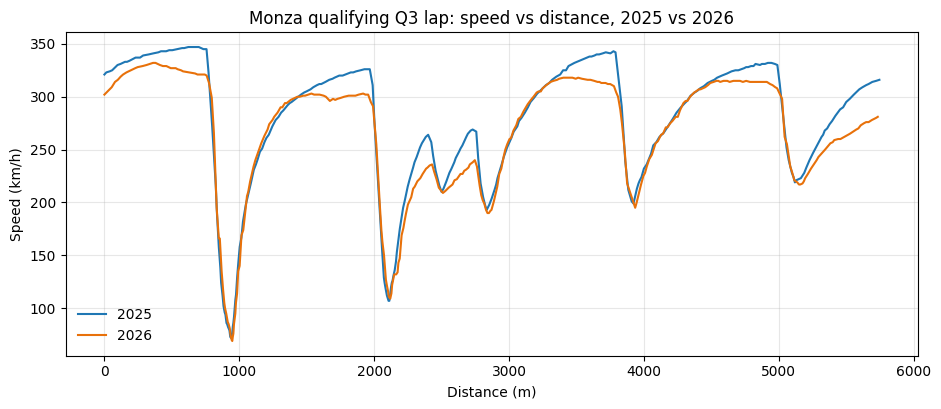

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

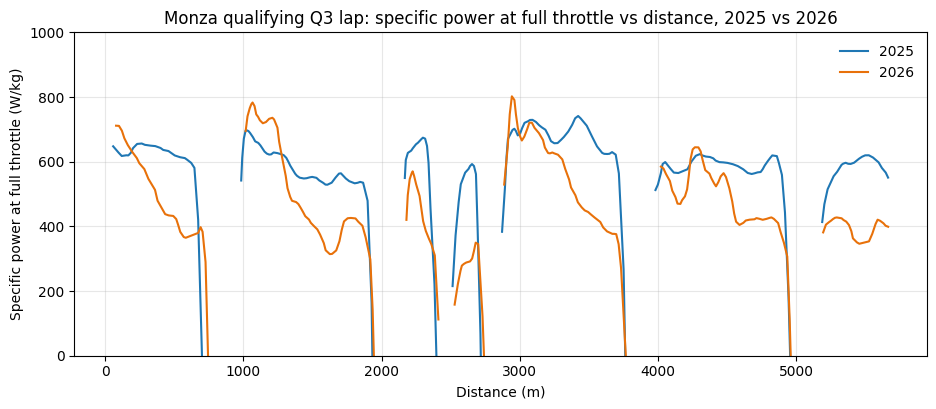

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Monza: final gap 2.893 s (lap times say 2.893 s)
2026 loses 3.26 s on red stretches and gains 0.37 s on green stretches


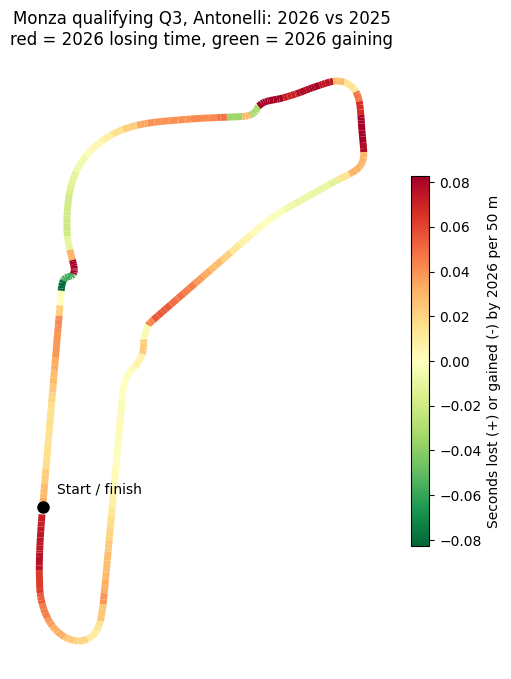

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

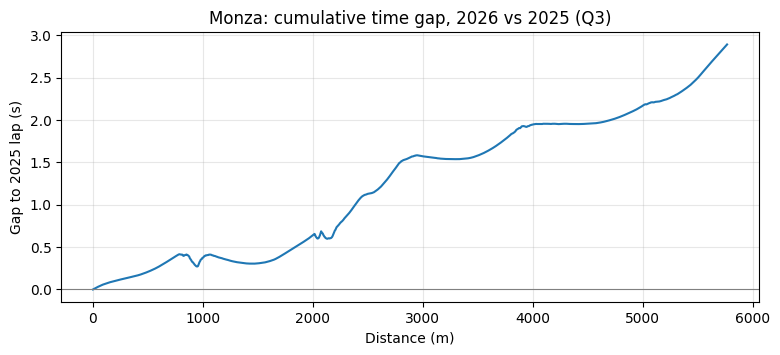

In [14]:
print('Top speed 2025 Q3:', monza25['speed'].max(), 'km/h')
print('Top speed 2026 Q3:', monza26['speed'].max(), 'km/h')

tab = pd.concat([straight_table(monza25, '2025'), straight_table(monza26, '2026')], ignore_index=True)
print(tab.to_string(index=False))
tab.to_csv('monza_q3_straights_table.csv', index=False)

cmp_ = pd.concat([binned_power(monza25, '2025'), binned_power(monza26, '2026')], axis=1)
cmp_['diff_pct'] = (100 * (cmp_['2026'] - cmp_['2025']) / cmp_['2025']).round(0)
print(cmp_.round(0))

save_plots(monza25, monza26, 'monza_q3',
           speed_title='Monza qualifying Q3 lap: speed vs distance, 2025 vs 2026',
           power_title='Monza qualifying Q3 lap: specific power at full throttle vs distance, 2025 vs 2026')

track_map(monza25, monza26, 'Monza', 'monza_q3_track_map.png')

Top speed 2025 Q3: 333 km/h
Top speed 2026 Q3: 331 km/h
year  start_m  end_m  v_start  v_end  P_start  P_end  drop_pct  clip_speed
2025     1355   1807      204    310      571    435        24         NaN
2025     2077   2476      209    289      618    355        43       289.0
2025     2821   3674      213    333      749    519        31       326.0
2026     1364   1805      209    295      702    281        60       295.0
2026     2099   2482      214    289      724    243        66       288.0
2026     2792   3671      213    316      786    308        61       329.0


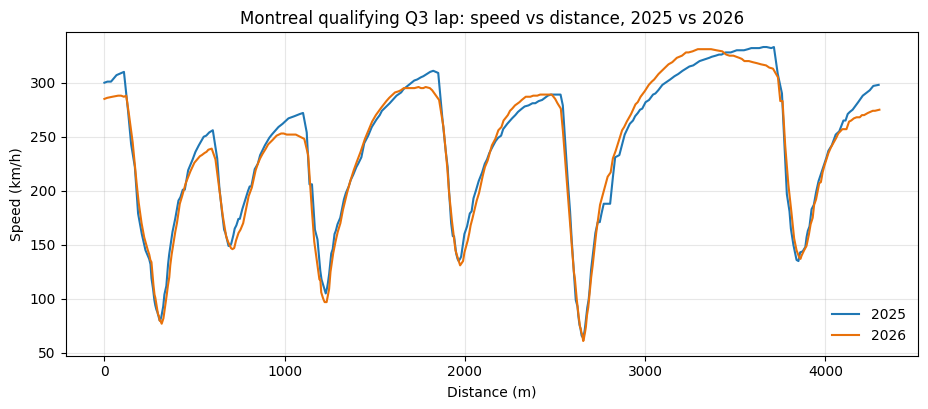

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

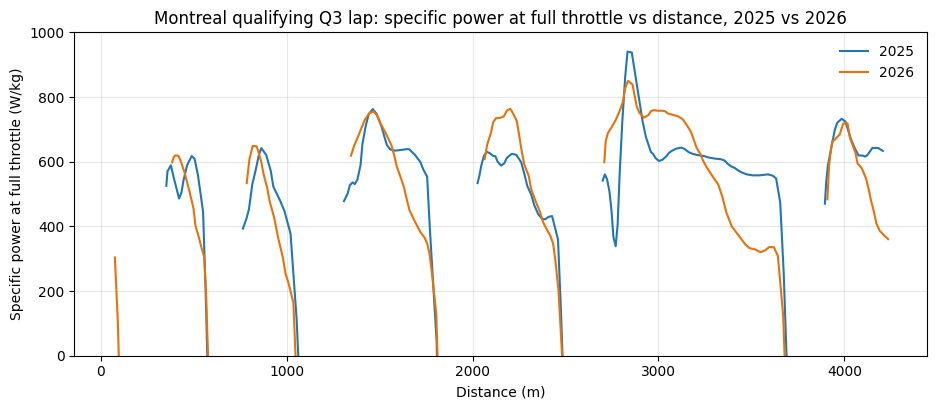

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Montreal: final gap 1.255 s (lap times say 1.255 s)
2026 loses 2.44 s on red stretches and gains 1.19 s on green stretches


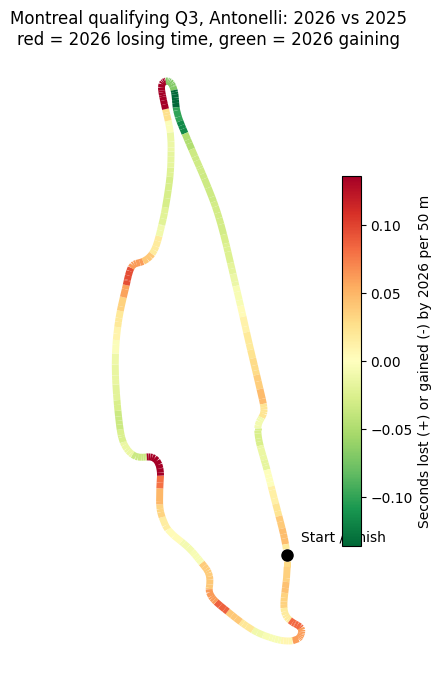

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

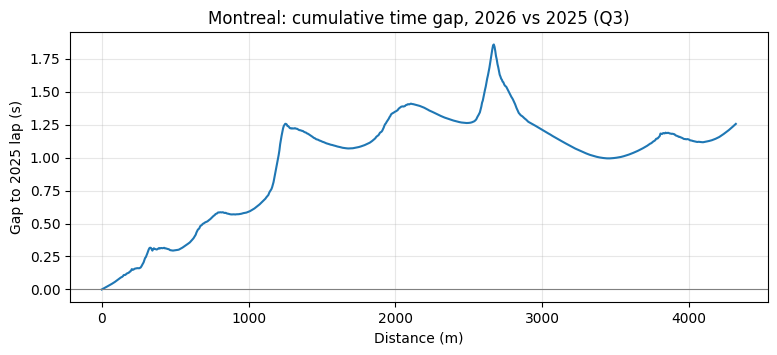

In [15]:
print('Top speed 2025 Q3:', mtl25['speed'].max(), 'km/h')
print('Top speed 2026 Q3:', mtl26['speed'].max(), 'km/h')

tab_m = pd.concat([straight_table(mtl25, '2025'), straight_table(mtl26, '2026')], ignore_index=True)
print(tab_m.to_string(index=False))
tab_m.to_csv('montreal_q3_straights_table.csv', index=False)

save_plots(mtl25, mtl26, 'montreal_q3',
           speed_title='Montreal qualifying Q3 lap: speed vs distance, 2025 vs 2026',
           power_title='Montreal qualifying Q3 lap: specific power at full throttle vs distance, 2025 vs 2026')

track_map(mtl25, mtl26, 'Montreal', 'montreal_q3_track_map.png')


In [16]:
def add_traffic(c, near_m=150.0, window_m=500.0):
    """For every telemetry sample: distance to the nearest car AHEAD on the same stretch of track.
    Adds c['gap_ahead_m'] (NaN if no car within window_m) and c['traffic'] (True if within near_m)."""
    a_ = c.attrs
    loc = get('location', f"session_key={a_['key']}&date>={fmt(a_['start'])}&date<={fmt(a_['end'])}")
    loc['t'] = (pd.to_datetime(loc['date'], format='ISO8601') - a_['start']).dt.total_seconds()
    tc = (c['date'] - a_['start']).dt.total_seconds().values

    def path(drv, clamp=False):
        d = loc[loc['driver_number'] == drv].sort_values('t').drop_duplicates('t')
        if len(d) < 5:
            return None
        kw = {} if clamp else dict(left=np.nan, right=np.nan)
        return np.interp(tc, d['t'], d['x'], **kw), np.interp(tc, d['t'], d['y'], **kw)

    # metres per x,y unit: compare the x,y path length with the speed-integrated lap length
    me = loc[loc['driver_number'] == a_['num']].sort_values('t')
    scale = c['Distance'].iloc[-1] / np.hypot(np.diff(me['x']), np.diff(me['y'])).sum()

    ax, ay = path(a_['num'], clamp=True)
    hx = pd.Series(np.gradient(ax, tc)).rolling(5, center=True, min_periods=1).mean().values
    hy = pd.Series(np.gradient(ay, tc)).rolling(5, center=True, min_periods=1).mean().values
    hn = np.hypot(hx, hy)
    hx, hy = hx / hn, hy / hn                                  # our direction of travel

    best = np.full(len(tc), np.inf)
    for drv in loc['driver_number'].unique():
        if drv == a_['num']:
            continue
        p = path(drv)
        if p is None:
            continue
        ox, oy = p
        rx, ry = (ox - ax) * scale, (oy - ay) * scale          # other car relative to us, metres
        dist = np.hypot(rx, ry)
        ahead = rx * hx + ry * hy > 0                          # in front of us
        same_dir = np.gradient(ox, tc) * hx + np.gradient(oy, tc) * hy > 0   # going the same way
        ok = ahead & same_dir & (dist <= window_m)
        best = np.where(ok & (dist < best), dist, best)

    c['gap_ahead_m'] = np.where(np.isinf(best), np.nan, best)
    c['traffic'] = c['gap_ahead_m'] <= near_m
    c.attrs['near_m'] = near_m
    return c


def traffic_report(c, label):
    f = c['traffic'].astype(bool)
    rid = (f != f.shift()).cumsum()
    print(f"{label}: car ahead within {c.attrs['near_m']:.0f} m on {100 * f.mean():.0f}% of the lap")
    for _, g in c[f].groupby(rid[f]):
        print(f"   {g['Distance'].iloc[0]:5.0f} to {g['Distance'].iloc[-1]:5.0f} m, closest {g['gap_ahead_m'].min():.0f} m")


for c, label in [(monza25, 'Monza 2025'), (monza26, 'Monza 2026'), (mtl25, 'Montreal 2025'), (mtl26, 'Montreal 2026')]:
    add_traffic(c)
    traffic_report(c, label)
    time.sleep(2)

Monza 2025: car ahead within 150 m on 2% of the lap
      39 to   153 m, closest 19 m
Monza 2026: car ahead within 150 m on 3% of the lap
      24 to    79 m, closest 29 m
     121 to   121 m, closest 26 m
     164 to   196 m, closest 19 m
    5648 to  5722 m, closest 87 m
Montreal 2025: car ahead within 150 m on 7% of the lap
    3888 to  3888 m, closest 150 m
    3902 to  4100 m, closest 10 m
    4124 to  4151 m, closest 10 m
    4207 to  4207 m, closest 8 m
Montreal 2026: car ahead within 150 m on 5% of the lap
    3882 to  3882 m, closest 118 m
    3937 to  3975 m, closest 28 m
    4017 to  4017 m, closest 44 m
    4060 to  4158 m, closest 11 m


In [17]:
for yr in (2025, 2026):
    s = get('sessions', f'year={yr}&circuit_short_name=Monza')
    key = int(s.loc[s['session_name'] == 'Qualifying', 'session_key'].iloc[0])
    d = get('drivers', f'session_key={key}')
    for acr in ('ANT', 'RUS'):
        num = int(d.loc[d['name_acronym'] == acr, 'driver_number'].iloc[0])
        st = get('stints', f'session_key={key}&driver_number={num}')
        print(yr, acr, st[['stint_number', 'compound', 'lap_start', 'lap_end']].to_string(index=False))

rus25 = pull_best_lap(2025, 'Monza', acr='RUS', segment='Q3')
time.sleep(2)
rus26 = pull_best_lap(2026, 'Monza', acr='RUS', segment='Q3')

print(pd.concat([straight_table(rus25, '2025'), straight_table(rus26, '2026')], ignore_index=True).to_string(index=False))
cmp_r = pd.concat([binned_power(rus25, '2025'), binned_power(rus26, '2026')], axis=1)
cmp_r['diff_pct'] = (100 * (cmp_r['2026'] - cmp_r['2025']) / cmp_r['2025']).round(0)
print(cmp_r.round(0))

2025 ANT  stint_number compound  lap_start  lap_end
            1   MEDIUM          1        7
            2     SOFT          8       10
            3     SOFT         11       13
            4     SOFT         14       16
            5     SOFT         17       19
            6     SOFT         20       22
2025 RUS  stint_number compound  lap_start  lap_end
            1   MEDIUM          1        3
            2   MEDIUM          4        6
            3     SOFT          7        9
            4     SOFT         10       12
            5     SOFT         13       15
            6     SOFT         16       18
2026 ANT  stint_number compound  lap_start  lap_end
            1     SOFT          1        3
            2     SOFT          4        5
            3     SOFT          6        8
            4     SOFT          9       11
            5     SOFT         12       13
            6     SOFT         14       16
            7     SOFT         17       18
2026 RUS  stint_number comp

2026 Monza NOR #1 Q3: lap 15, 82.256 s, 310 samples, 5731 m
year  start_m  end_m  v_start  v_end  P_start  P_end  drop_pct  clip_speed
 NOR        0    718      301    322      713    426        40       328.0
 NOR     1073   1911      210    303      726    350        52       299.0
 NOR     2891   3708      208    320      751    382        49       326.0
 NOR     4013   4952      222    310      627    380        39       312.0
 NOR     5186   5684      209    280      438    444        -1         NaN


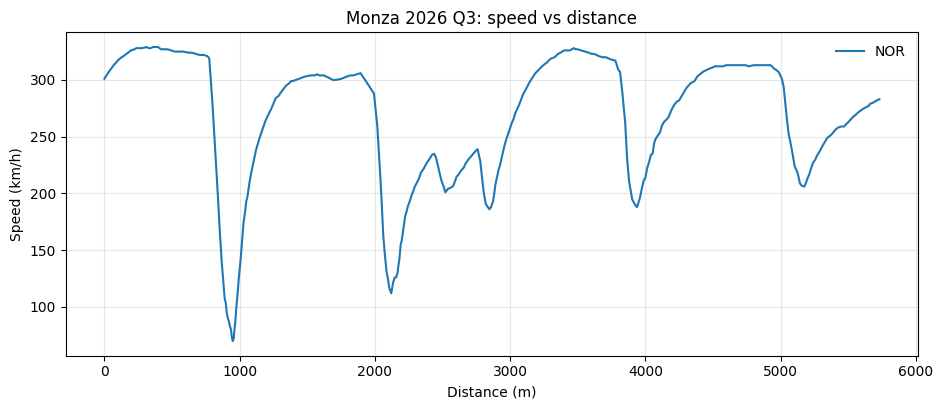

In [18]:
drivers26 = ['NOR']          # change to whichever drivers you want to compare
laps26 = {}
for acr in drivers26:
    try:
        laps26[acr] = pull_best_lap(2026, 'Monza', acr=acr, segment='Q3')
    except Exception as e:
        print(acr, 'skipped:', e)                  # e.g. no Q3 lap
    time.sleep(2)

print(pd.concat([straight_table(laps26[a], a) for a in laps26], ignore_index=True).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4.2))
for a in laps26:
    ax.plot(laps26[a]['Distance'], laps26[a]['speed'], label=a)
ax.set_xlabel('Distance (m)'); ax.set_ylabel('Speed (km/h)')
ax.set_title('Monza 2026 Q3: speed vs distance')
ax.legend(frameon=False); ax.grid(alpha=0.3)
plt.show()